# Lecture 14: GDA and QDA decision boundaries

**CSCI 6032 · Gaussian Discriminant Analysis**

Both classifiers model each class with a Gaussian and pick the class with the larger $f_{\bar\mu_y,\Sigma_y}(\bar x)\,P(y)$, rule (11) in the notes. They differ in one assumption:

- **GDA** assumes every class has the **same** covariance $\Sigma$ (homoscedasticity). The decision boundary is always a line (a hyperplane in $n$ dimensions).
- **QDA** gives each class its own covariance $\Sigma_0, \Sigma_1$. The boundary can be any conic: an ellipse, a hyperbola, or, as in this notebook, a **parabola**.

We build a two-class dataset whose *true* best boundary is a parabola, fit both models from scratch with NumPy, and compare their boundaries and accuracy.

## 1. A dataset whose optimal boundary is a parabola

Class 0 is a round Gaussian. Class 1 sits two units higher and is twice as wide in $x_1$ (variance 4 instead of 1):

$$\bar\mu_0=\begin{bmatrix}0\\0\end{bmatrix},\;
\Sigma_0=\begin{bmatrix}1&0\\0&1\end{bmatrix},\qquad
\bar\mu_1=\begin{bmatrix}0\\2\end{bmatrix},\;
\Sigma_1=\begin{bmatrix}4&0\\0&1\end{bmatrix},\qquad
P(y=0)=P(y=1)=\tfrac12 .$$

With equal priors, the minimum-error rule picks class 1 when $\ln f_1(\bar x)-\ln f_0(\bar x)>0$. Using
$\ln f_{\bar\mu,\Sigma}(\bar x)=-\tfrac12\ln\lvert2\pi\Sigma\rvert-\tfrac12(\bar x-\bar\mu)^T\Sigma^{-1}(\bar x-\bar\mu)$ and $\lvert\Sigma_1\rvert=4$, $\lvert\Sigma_0\rvert=1$:

$$\ln f_1-\ln f_0
=-\tfrac12\ln4-\tfrac12\Big[\tfrac{x_1^2}{4}+(x_2-2)^2\Big]+\tfrac12\big[x_1^2+x_2^2\big]
=\tfrac38x_1^2+2x_2-2-\ln2 .$$

Setting this to zero gives the **Bayes (optimal) decision boundary**

$$\boxed{x_2=1+\tfrac{\ln2}{2}-\tfrac{3}{16}\,x_1^2}$$

a downward-opening parabola. Class 1 wins above it. Because class 1 is wider, it also wins far out to the left and right, where the parabola has dropped below class 0.

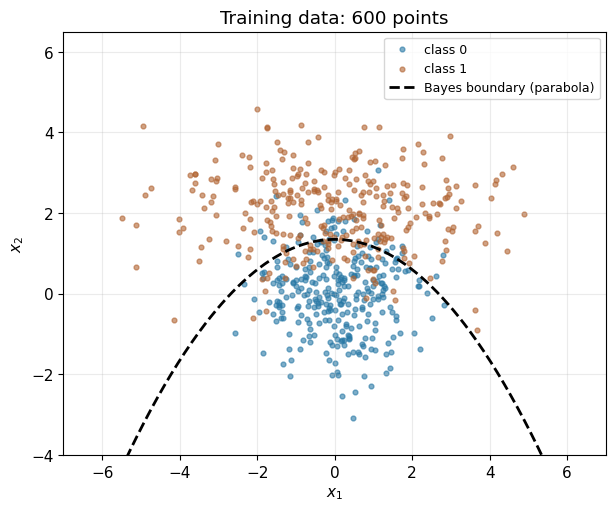

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal

plt.rcParams.update({"figure.figsize": (12, 5), "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 11})
COLORS = ["#2878a5", "#b16432"]          # class 0, class 1

MU = [np.array([0.0, 0.0]), np.array([0.0, 2.0])]
SIGMA = [np.diag([1.0, 1.0]), np.diag([4.0, 1.0])]

def sample(n_per_class, rng):
    X = np.vstack([rng.multivariate_normal(MU[k], SIGMA[k], n_per_class) for k in (0, 1)])
    y = np.repeat([0, 1], n_per_class)
    return X, y

def bayes_boundary(x1):
    return 1 + np.log(2) / 2 - 3 / 16 * x1**2

rng = np.random.default_rng(6032)
X_train, y_train = sample(300, rng)
X_test, y_test = sample(5000, rng)

x1_line = np.linspace(-7, 7, 400)
fig, ax = plt.subplots(figsize=(7, 5.5))
for k in (0, 1):
    pts = X_train[y_train == k]
    ax.scatter(pts[:, 0], pts[:, 1], s=12, alpha=0.6, color=COLORS[k], label=f"class {k}")
ax.plot(x1_line, bayes_boundary(x1_line), "k--", lw=2, label="Bayes boundary (parabola)")
ax.set(xlim=(-7, 7), ylim=(-4, 6.5), xlabel="$x_1$", ylabel="$x_2$",
       title=f"Training data: {len(y_train)} points")
ax.legend(loc="upper right", fontsize=9)
plt.show()

## 2. Fitting GDA and QDA

Both fits are maximum-likelihood estimates: the class prior is the fraction of training points in class 1, each mean is the class average, and each covariance is an average of outer products $(\bar x-\bar\mu)(\bar x-\bar\mu)^T$.

- **GDA** pools all points, each centred on its *own* class mean, into one $\Sigma$.
- **QDA** averages within each class separately to get $\Sigma_0$ and $\Sigma_1$.

The classifier computes rule (11) in log form, which avoids underflow and gives the same decisions because $\ln$ is increasing:

$$\text{score}(\bar x)=\big[\ln f_1(\bar x)+\ln P(y=1)\big]-\big[\ln f_0(\bar x)+\ln P(y=0)\big],
\qquad \hat y=\begin{cases}1&\text{score}\ge0\\0&\text{otherwise}\end{cases}$$

In [2]:
def log_gaussian(X, mu, Sigma):
    # ln f_{mu,Sigma}(x) for every row x of X.
    d = X - mu
    maha = np.sum(d * np.linalg.solve(Sigma, d.T).T, axis=1)   # (x-mu)^T Sigma^{-1} (x-mu)
    _, logdet = np.linalg.slogdet(2 * np.pi * Sigma)
    return -0.5 * (logdet + maha)

def fit(X, y, shared_covariance):
    prior1 = y.mean()
    mus = [X[y == k].mean(axis=0) for k in (0, 1)]
    scatter = [(X[y == k] - mus[k]).T @ (X[y == k] - mus[k]) for k in (0, 1)]
    if shared_covariance:                       # GDA: one pooled Sigma
        sigmas = [(scatter[0] + scatter[1]) / len(y)] * 2
    else:                                       # QDA: Sigma_0, Sigma_1
        sigmas = [scatter[k] / np.sum(y == k) for k in (0, 1)]
    return {"priors": [1 - prior1, prior1], "mus": mus, "sigmas": sigmas}

def score(model, X):
    s = [log_gaussian(X, model["mus"][k], model["sigmas"][k]) + np.log(model["priors"][k])
         for k in (0, 1)]
    return s[1] - s[0]

def predict(model, X):
    return (score(model, X) >= 0).astype(int)

# Check log_gaussian against SciPy before relying on it.
for k in (0, 1):
    np.testing.assert_allclose(log_gaussian(X_test[:50], MU[k], SIGMA[k]),
                               multivariate_normal(MU[k], SIGMA[k]).logpdf(X_test[:50]))

gda = fit(X_train, y_train, shared_covariance=True)
qda = fit(X_train, y_train, shared_covariance=False)

np.set_printoptions(precision=3, suppress=True)
for name, m in [("GDA", gda), ("QDA", qda)]:
    print(f"{name}:  P(y=1) = {m['priors'][1]:.3f}   mu_0 = {m['mus'][0]}   mu_1 = {m['mus'][1]}")
    if name == "GDA":
        print(f"      Sigma =\n{m['sigmas'][0]}")
    else:
        print(f"      Sigma_0 =\n{m['sigmas'][0]}\n      Sigma_1 =\n{m['sigmas'][1]}")
    print()

GDA:  P(y=1) = 0.500   mu_0 = [0.065 0.015]   mu_1 = [-0.036  2.059]
      Sigma =
[[ 2.571 -0.082]
 [-0.082  0.95 ]]

QDA:  P(y=1) = 0.500   mu_0 = [0.065 0.015]   mu_1 = [-0.036  2.059]
      Sigma_0 =
[[ 1.063 -0.041]
 [-0.041  0.973]]
      Sigma_1 =
[[ 4.078 -0.123]
 [-0.123  0.928]]



GDA's single $\Sigma$ is roughly the average of the two true covariances, about $\mathrm{diag}(2.5,1)$. It cannot represent the fact that class 1 is wider than class 0. QDA recovers both shapes.

## 3. What each model believes: the fitted class densities

Each ellipse below is a contour of a fitted $f_{\bar\mu_y,\Sigma_y}$. Under GDA both classes are forced into the same shape, only shifted. Under QDA, class 1's contours are stretched sideways.

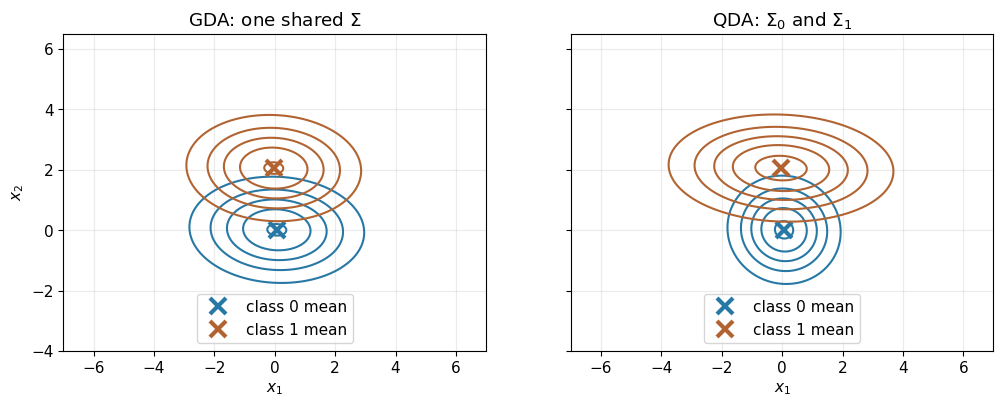

In [3]:
g1, g2 = np.meshgrid(np.linspace(-7, 7, 400), np.linspace(-4, 6.5, 300))
grid = np.column_stack([g1.ravel(), g2.ravel()])

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, (name, m) in zip(axes, [("GDA: one shared $\\Sigma$", gda), ("QDA: $\\Sigma_0$ and $\\Sigma_1$", qda)]):
    for k in (0, 1):
        dens = np.exp(log_gaussian(grid, m["mus"][k], m["sigmas"][k])).reshape(g1.shape)
        ax.contour(g1, g2, dens, levels=5, colors=COLORS[k], linewidths=1.5)
        ax.plot(*m["mus"][k], "x", color=COLORS[k], ms=12, mew=3, label=f"class {k} mean")
    ax.set(title=name, xlabel="$x_1$", xlim=(-7, 7), ylim=(-4, 6.5), aspect="equal")
    ax.legend(loc="lower center")
axes[0].set_ylabel("$x_2$")
plt.show()

## 4. Decision boundaries and accuracy

The shading shows which class each model predicts; the solid line is the model's boundary $\text{score}(\bar x)=0$; the dashed line is the Bayes parabola from Section 1. Accuracy is measured on a separate test set of 10,000 points. The Bayes boundary's accuracy is the best any classifier can do on average for this distribution.

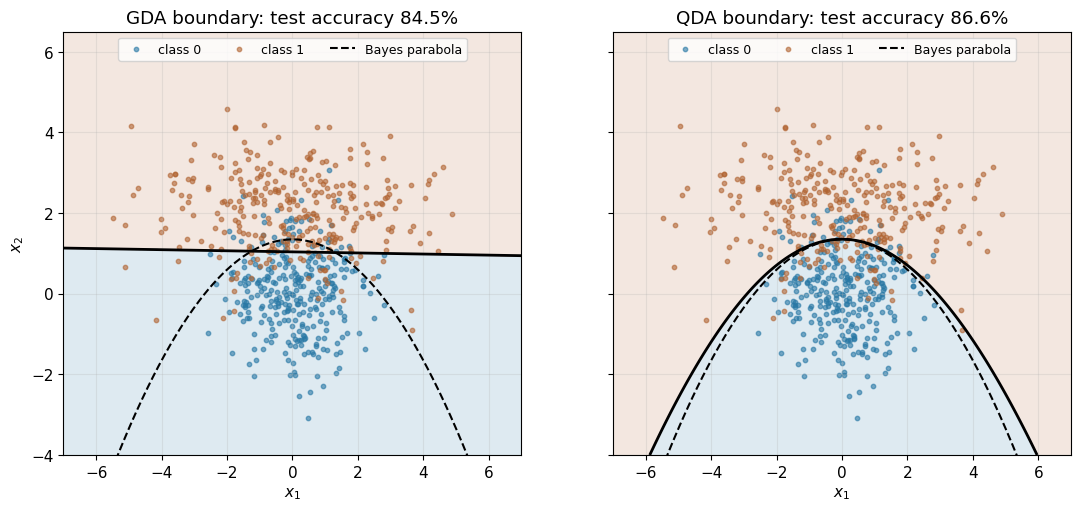

  GDA test accuracy: 84.53%
  QDA test accuracy: 86.64%
Bayes test accuracy: 86.59%


In [4]:
def accuracy(y_hat, y):
    return np.mean(y_hat == y)

bayes_pred = (X_test[:, 1] >= bayes_boundary(X_test[:, 0])).astype(int)
acc = {"GDA": accuracy(predict(gda, X_test), y_test),
       "QDA": accuracy(predict(qda, X_test), y_test),
       "Bayes": accuracy(bayes_pred, y_test)}

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
for ax, (name, m) in zip(axes, [("GDA", gda), ("QDA", qda)]):
    s = score(m, grid).reshape(g1.shape)
    ax.contourf(g1, g2, s >= 0, levels=[-0.5, 0.5, 1.5], colors=COLORS, alpha=0.15)
    ax.contour(g1, g2, s, levels=[0], colors="k", linewidths=2)
    for k in (0, 1):
        pts = X_train[y_train == k]
        ax.scatter(pts[:, 0], pts[:, 1], s=10, alpha=0.6, color=COLORS[k], label=f"class {k}")
    ax.plot(x1_line, bayes_boundary(x1_line), "k--", lw=1.5, label="Bayes parabola")
    ax.set(title=f"{name} boundary: test accuracy {acc[name]:.1%}", xlabel="$x_1$",
           xlim=(-7, 7), ylim=(-4, 6.5))
    ax.legend(loc="upper center", ncol=3, fontsize=9)
axes[0].set_ylabel("$x_2$")
plt.show()

for name, a in acc.items():
    print(f"{name:>5} test accuracy: {a:.2%}")
assert acc["QDA"] > acc["GDA"]

GDA draws a straight line at roughly $x_2\approx1$. It gets the middle right but assigns every class-1 point in the outer "wings" (large $\lvert x_1\rvert$, low $x_2$) to class 0. QDA bends its boundary down on both sides, nearly on top of the Bayes parabola, and matches the Bayes accuracy to within test-set noise. (On a finite test set, a fitted model can even beat the Bayes boundary by a hair through luck; the Bayes boundary is optimal on *average* over the distribution.)

The gap between GDA and QDA is only a couple of percent because few points fall in the wings. Section 6 suggests ways to make the difference larger.

## 5. Why GDA is linear and QDA is quadratic

Expand the score. Every term in $\ln f_k$ that does not involve $\bar x$ is a constant, so

$$\text{score}(\bar x)=\bar x^TA\,\bar x+\bar b^T\bar x+c,
\qquad A=-\tfrac12\big(\Sigma_1^{-1}-\Sigma_0^{-1}\big),
\qquad \bar b=\Sigma_1^{-1}\bar\mu_1-\Sigma_0^{-1}\bar\mu_0 .$$

- **GDA:** $\Sigma_0=\Sigma_1=\Sigma$, so $A=0$. The quadratic term cancels and $\bar b^T\bar x+c=0$ is a line.
- **QDA:** $A\neq0$ in general, so the boundary is a conic. For two features, the sign of $\det A$ decides which one: $\det A>0$ gives an ellipse, $\det A<0$ a hyperbola, and $\det A=0$ a **parabola** (or a degenerate pair of lines).

For our true covariances, $\Sigma_1^{-1}-\Sigma_0^{-1}=\mathrm{diag}(\tfrac14-1,\;1-1)=\mathrm{diag}(-\tfrac34,0)$. The class shapes differ only along $x_1$, so $A$ has one zero eigenvalue and $\det A=0$: exactly a parabola. With covariances estimated from data, $\det A$ is tiny but not exactly zero. The fitted boundary is then technically a very flat ellipse or hyperbola that is indistinguishable from a parabola over the plotted region.

In [5]:
def quadratic_form(m):
    inv = [np.linalg.inv(S) for S in m["sigmas"]]
    A = -0.5 * (inv[1] - inv[0])
    b = inv[1] @ m["mus"][1] - inv[0] @ m["mus"][0]
    return A, b

A_true = -0.5 * (np.linalg.inv(SIGMA[1]) - np.linalg.inv(SIGMA[0]))
print("True A =\n", A_true, "\neigenvalues:", np.linalg.eigvalsh(A_true), "  det A =", np.linalg.det(A_true))
for name, m in [("GDA", gda), ("QDA", qda)]:
    A, b = quadratic_form(m)
    print(f"\n{name} fitted A =\n{A}\neigenvalues: {np.linalg.eigvalsh(A)}   det A = {np.linalg.det(A):.4f}")

assert np.allclose(quadratic_form(gda)[0], 0)          # shared covariance: no quadratic term

True A =
 [[ 0.375 -0.   ]
 [-0.    -0.   ]] 
eigenvalues: [-0.     0.375]   det A = 0.0

GDA fitted A =
[[-0. -0.]
 [-0. -0.]]
eigenvalues: [-0. -0.]   det A = 0.0000

QDA fitted A =
[[ 0.348  0.003]
 [ 0.003 -0.027]]
eigenvalues: [-0.027  0.348]   det A = -0.0093


## 6. Two counterintuitive QDA boundaries

The parabola came from classes that differ in shape along only one direction. When the shapes differ in **both** directions, $\det A\neq0$ and the boundary becomes an ellipse or a hyperbola. Both cases surprise people the first time they see them.

The helper below repeats Sections 2–4 for any pair of true Gaussians. It samples training and test sets, fits GDA and QDA, and draws both boundaries. The dashed curve is now the Bayes boundary computed directly from the true parameters, which is the zero contour of the true score.

In [6]:
def sample_from(mus, sigmas, n_per_class, rng):
    X = np.vstack([rng.multivariate_normal(mus[k], sigmas[k], n_per_class) for k in (0, 1)])
    return X, np.repeat([0, 1], n_per_class)

def true_score(X, mus, sigmas):
    # Bayes score with equal priors: ln f_1(x) - ln f_0(x) under the TRUE parameters.
    return log_gaussian(X, mus[1], sigmas[1]) - log_gaussian(X, mus[0], sigmas[0])

def compare(mus, sigmas, lims, seed, marks=()):
    rng = np.random.default_rng(seed)
    X_tr, y_tr = sample_from(mus, sigmas, 300, rng)
    X_te, y_te = sample_from(mus, sigmas, 5000, rng)
    models = {"GDA": fit(X_tr, y_tr, shared_covariance=True),
              "QDA": fit(X_tr, y_tr, shared_covariance=False)}
    acc = {name: accuracy(predict(m, X_te), y_te) for name, m in models.items()}
    acc["Bayes"] = accuracy((true_score(X_te, mus, sigmas) >= 0).astype(int), y_te)

    h1, h2 = np.meshgrid(np.linspace(*lims[0], 400), np.linspace(*lims[1], 400))
    pts = np.column_stack([h1.ravel(), h2.ravel()])
    bayes = true_score(pts, mus, sigmas).reshape(h1.shape)
    fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
    for ax, (name, m) in zip(axes, models.items()):
        s = score(m, pts).reshape(h1.shape)
        ax.contourf(h1, h2, s >= 0, levels=[-0.5, 0.5, 1.5], colors=COLORS, alpha=0.15)
        ax.contour(h1, h2, s, levels=[0], colors="k", linewidths=2)
        ax.contour(h1, h2, bayes, levels=[0], colors="k", linewidths=1.5, linestyles="--")
        for k in (0, 1):
            p = X_tr[y_tr == k]
            ax.scatter(p[:, 0], p[:, 1], s=10, alpha=0.5, color=COLORS[k], label=f"class {k}")
        for x, label in marks:
            ax.plot(*x, "k*", ms=16)
            ax.annotate(label, x, xytext=(8, 8), textcoords="offset points", fontsize=10,
                        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85))
        ax.plot([], [], "k-", lw=2, label=f"{name} boundary")
        ax.plot([], [], "k--", lw=1.5, label="Bayes boundary")
        ax.set(title=f"{name}: test accuracy {acc[name]:.1%}", xlabel="$x_1$",
               xlim=lims[0], ylim=lims[1], aspect="equal")
        ax.legend(loc="upper right", fontsize=9)
    axes[0].set_ylabel("$x_2$")
    plt.show()
    for name, a in acc.items():
        print(f"{name:>5} test accuracy: {a:.2%}")
    return models, acc

def true_A(sigmas):
    return -0.5 * (np.linalg.inv(sigmas[1]) - np.linalg.inv(sigmas[0]))

### 6a. A broad class surrounds a narrow one: an ellipse

Class 0 is tight around the origin. Class 1 is centred to the **right**, at $(2,0)$, but is three times as spread out in every direction:

$$\bar\mu_0=\begin{bmatrix}0\\0\end{bmatrix},\;\Sigma_0=I,\qquad
\bar\mu_1=\begin{bmatrix}2\\0\end{bmatrix},\;\Sigma_1=9I .$$

Following the same algebra as Section 1, $\ln f_1-\ln f_0=0$ simplifies to a circle:

$$\big(x_1+\tfrac14\big)^2+x_2^2=\tfrac9{16}+\tfrac94\ln9\approx(2.35)^2 .$$

Class 0 wins only **inside** that circle; class 1 wins everywhere else, on every side. The counterintuitive part: the starred point $(-5,0)$ is 5 units from $\bar\mu_0$ and 7 units from $\bar\mu_1$, *on the far side of class 0 from class 1*, yet it is classified as class 1. Class 0 is so concentrated that a point 5 standard deviations out is essentially impossible under it. Class 1, with standard deviation 3, still assigns it a reasonable density. Notice also that the circle's centre, $(-\tfrac14,0)$, is pushed slightly *away* from class 1.

GDA cannot express "one class inside, the other outside": its boundary is a single straight line.

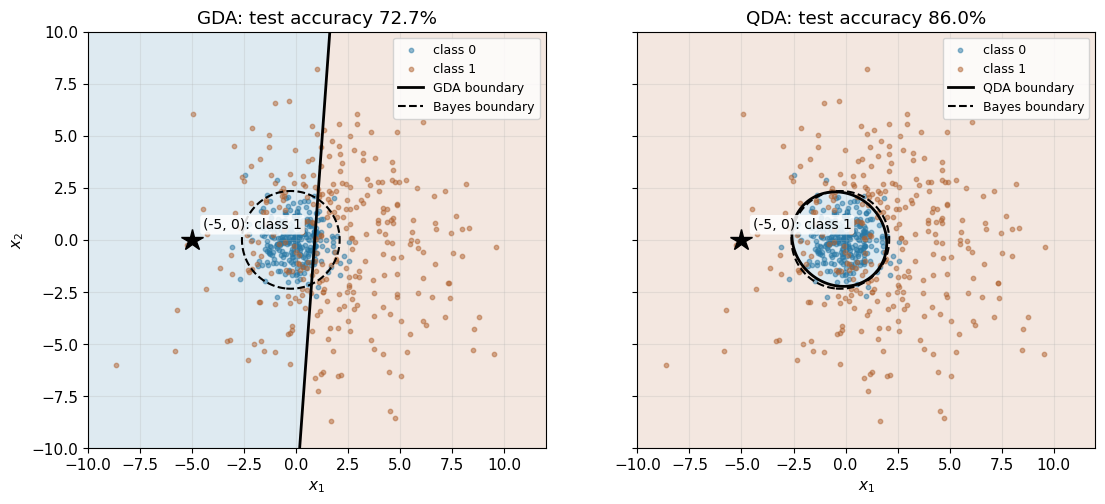

  GDA test accuracy: 72.71%
  QDA test accuracy: 86.04%
Bayes test accuracy: 85.91%

distance to mu_0 = 5, distance to mu_1 = 7, true P(y=1 | x) = 0.9995
true A =
 [[ 0.444 -0.   ]
 [-0.     0.444]]   det A = 0.19753086419753085 (> 0: ellipse)


In [7]:
MU_A = [np.array([0.0, 0.0]), np.array([2.0, 0.0])]
SIGMA_A = [np.eye(2), 9 * np.eye(2)]
far_left = np.array([-5.0, 0.0])

models_a, acc_a = compare(MU_A, SIGMA_A, lims=((-10, 12), (-10, 10)), seed=1,
                          marks=[(far_left, "(-5, 0): class 1")])

d0, d1 = np.linalg.norm(far_left - MU_A[0]), np.linalg.norm(far_left - MU_A[1])
post1 = 1 / (1 + np.exp(-true_score(far_left[None], MU_A, SIGMA_A)[0]))
print(f"\ndistance to mu_0 = {d0:.0f}, distance to mu_1 = {d1:.0f}, true P(y=1 | x) = {post1:.4f}")
print("true A =\n", true_A(SIGMA_A), "  det A =", np.linalg.det(true_A(SIGMA_A)), "(> 0: ellipse)")

assert d0 < d1 and post1 > 0.99
assert np.linalg.det(true_A(SIGMA_A)) > 0
assert acc_a["QDA"] > acc_a["GDA"]

### 6b. A tilted class pokes through a round one: a hyperbola

Now give both classes the **same mean**, so a classifier cannot use location at all. Class 0 is round. Class 1 has variance 4 in each coordinate and a correlation of $0.95$, so it is a long, thin cigar along the diagonal:

$$\bar\mu_0=\bar\mu_1=\begin{bmatrix}0\\0\end{bmatrix},\qquad
\Sigma_0=I,\qquad
\Sigma_1=4\begin{bmatrix}1&0.95\\0.95&1\end{bmatrix}.$$

$\Sigma_1$'s eigenvectors point along the diagonals. Its eigenvalues are $4(1+0.95)=7.8$ along $(1,1)$ and $4(1-0.95)=0.2$ along $(1,-1)$. So class 1 is **wider** than class 0 along one diagonal and **narrower** along the other. In rotated coordinates $u=(x_1+x_2)/\sqrt2$ and $v=(x_1-x_2)/\sqrt2$, with $\lvert\Sigma_1\rvert=1.56$, the boundary $\ln f_1-\ln f_0=0$ is

$$\tfrac12\Big(1-\tfrac1{7.8}\Big)u^2-\tfrac12\Big(\tfrac1{0.2}-1\Big)v^2=\tfrac12\ln1.56
\quad\Longrightarrow\quad 0.436\,u^2-2\,v^2=0.222 ,$$

a **hyperbola**, because $u^2$ and $v^2$ have opposite signs ($\det A<0$). Class 1 wins in two wedges along the cigar's axis, where it extends past class 0. Class 0 wins across the cigar's narrow direction and at the centre, where class 0's density is higher.

The counterintuitive part: the two class-1 regions are **disconnected** wedges on opposite sides of the origin, and the starred points $(3,3)$ and $(-3,-3)$ go to class 1 while $(2,-2)$, which is closer to the shared mean, goes to class 0. With identical means, GDA has nothing to work with and does little better than a coin flip.

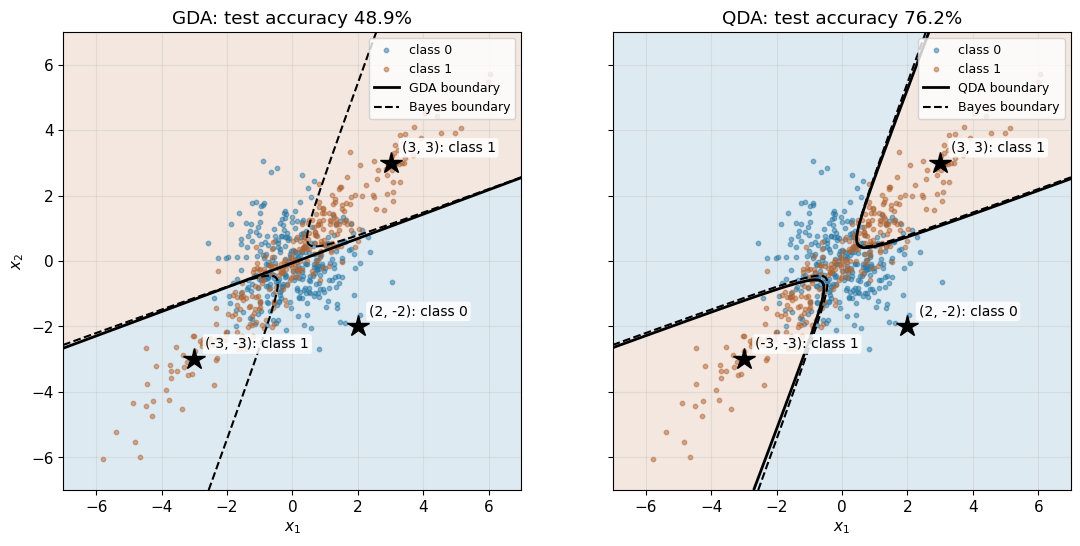

  GDA test accuracy: 48.88%
  QDA test accuracy: 76.24%
Bayes test accuracy: 76.61%

eigenvalues of Sigma_1: [0.2 7.8]
true A =
 [[-0.782  1.218]
 [ 1.218 -0.782]]   det A = -0.872 (< 0: hyperbola)
   (3, 3): class 1: true score =    7.62
 (-3, -3): class 1: true score =    7.62
  (2, -2): class 0: true score =  -16.22


In [8]:
MU_B = [np.zeros(2), np.zeros(2)]
SIGMA_B = [np.eye(2), 4 * np.array([[1.0, 0.95], [0.95, 1.0]])]
probe = {"(3, 3): class 1": np.array([3.0, 3.0]), "(-3, -3): class 1": np.array([-3.0, -3.0]),
         "(2, -2): class 0": np.array([2.0, -2.0])}

models_b, acc_b = compare(MU_B, SIGMA_B, lims=((-7, 7), (-7, 7)), seed=2,
                          marks=[(x, label) for label, x in probe.items()])

print("\neigenvalues of Sigma_1:", np.linalg.eigvalsh(SIGMA_B[1]))
print("true A =\n", true_A(SIGMA_B), "  det A =", round(np.linalg.det(true_A(SIGMA_B)), 3), "(< 0: hyperbola)")
for label, x in probe.items():
    print(f"{label:>18}: true score = {true_score(x[None], MU_B, SIGMA_B)[0]:7.2f}")

assert np.allclose(np.linalg.eigvalsh(SIGMA_B[1]), [0.2, 7.8])
assert np.linalg.det(true_A(SIGMA_B)) < 0
assert true_score(probe["(3, 3): class 1"][None], MU_B, SIGMA_B)[0] > 0
assert true_score(probe["(2, -2): class 0"][None], MU_B, SIGMA_B)[0] < 0
assert acc_b["QDA"] > acc_b["GDA"] + 0.1

Both examples make the same point from opposite directions. QDA's boundary is decided by **where each class's density is higher**, not by which mean is closer. When the classes differ in spread, a point can be closer to one mean and still belong to the other class, because the broader class "reaches" farther. GDA forces equal spreads, so it can only ever compare (scaled) distances to the means, and it misses both effects.

## 7. Try it yourself

- In Section 1's data, change `SIGMA[1]` to `np.diag([4.0, 4.0])`. Both directions now differ, $\det A>0$, and the QDA boundary closes into an **ellipse** around class 0, as in Section 6a.
- Try `np.diag([4.0, 0.25])`. Class 1 is wider in $x_1$ but narrower in $x_2$, so $\det A<0$ and the boundary becomes a **hyperbola**, an axis-aligned version of Section 6b.
- In Section 6b, lower the correlation from 0.95 toward 0. Once class 1's narrow-direction variance $4(1-\rho)$ exceeds 1 ($\rho<0.75$), class 1 is wider in every direction, $\det A>0$, and the hyperbola turns into an ellipse.
- Set `SIGMA[1] = SIGMA[0]`. Now GDA's assumption is true, so GDA and QDA should reach nearly the same accuracy, with QDA's boundary almost a straight line.
- Make class 1 even wider, e.g. `np.diag([9.0, 1.0])`. The parabola gets steeper, more class-1 points land in the wings, and GDA falls further behind.
- Reduce the training set to 20 points per class. QDA estimates more parameters than GDA (two covariance matrices instead of one), so with little data it can overfit and lose its advantage.